# Лабораторная 1

Импорт библиотек

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

Посмотрим данные

In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
ex = pd.read_csv("ex.csv")

In [4]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Ex shape:", ex.shape)

Train shape: (11017, 35)
Test shape: (5000, 35)
Ex shape: (5000, 2)


In [ ]:
display(train.head())
display(test.head())
display(ex.head())

Просмотрим список столбцов(пусть будет)

In [7]:
print("TRAIN:")
print(train.columns.tolist())

print("\nTEST:")
print(test.columns.tolist())

print("\nEX:")
print(ex.columns.tolist())

TRAIN:
['ApplicationDate', 'Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanDuration', 'MaritalStatus', 'NumberOfDependents', 'HomeOwnershipStatus', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHistory', 'LoanPurpose', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'EmploymentStatus', 'EducationLevel', 'Experience', 'NetWorth', 'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'RiskScore']

TEST:
['ID', 'ApplicationDate', 'Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanDuration', 'MaritalStatus', 'NumberOfDependents', 'HomeOwnershipStatus', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHisto

In [8]:
print("Первые ID в train:")
print(train["ID"].head() if "ID" in train.columns else "ID отсутствует")

print("\nПервые ID в test:")
print(test["ID"].head())

Первые ID в train:
ID отсутствует

Первые ID в test:
0    0
1    1
2    2
3    3
4    4
Name: ID, dtype: int64


ПРопуски всегда важно

In [9]:
print("Пропуски в train:")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\nПропуски в test:")
print(test.isnull().sum()[test.isnull().sum() > 0])

Пропуски в train:
ApplicationDate                530
Age                            530
AnnualIncome                   530
CreditScore                   1031
LoanAmount                    1031
LoanDuration                   530
MaritalStatus                  530
NumberOfDependents             530
HomeOwnershipStatus            530
MonthlyDebtPayments           1031
CreditCardUtilizationRate      530
NumberOfOpenCreditLines        530
NumberOfCreditInquiries        530
DebtToIncomeRatio              530
BankruptcyHistory             1031
LoanPurpose                   1031
PreviousLoanDefaults           530
PaymentHistory                 530
LengthOfCreditHistory          530
SavingsAccountBalance          530
CheckingAccountBalance        1031
TotalAssets                   1031
TotalLiabilities               530
MonthlyIncome                  530
UtilityBillsPaymentHistory     530
JobTenure                      530
EmploymentStatus               530
EducationLevel                 530
Ex

In [10]:
display(train["RiskScore"].describe())

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

## Анализ целевой переменной RiskScore

Аномалии

In [12]:
print("Количество пропусков:")
print(train["RiskScore"].isnull().sum())

print("\nКоличество отрицательных значений:")
print((train["RiskScore"] < 0).sum())

print("\nКоличество значений больше 100:")
print((train["RiskScore"] > 100).sum())

print("\n10 минимальных значений:")
print(train["RiskScore"].nsmallest(10))

print("\n10 максимальных значений:")
print(train["RiskScore"].nlargest(10))

Количество пропусков:
530

Количество отрицательных значений:
121

Количество значений больше 100:
94

10 минимальных значений:
33    -9999999.0
56    -9999999.0
83    -9999999.0
183   -9999999.0
198   -9999999.0
317   -9999999.0
517   -9999999.0
572   -9999999.0
671   -9999999.0
692   -9999999.0
Name: RiskScore, dtype: float64

10 максимальных значений:
237     10000000.0
398     10000000.0
657     10000000.0
1168    10000000.0
1253    10000000.0
1330    10000000.0
1343    10000000.0
1704    10000000.0
1712    10000000.0
1800    10000000.0
Name: RiskScore, dtype: float64


In [13]:
print(
    train["RiskScore"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
1%      -9.999999e+06
5%       2.598087e+01
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
95%      7.646136e+01
99%      9.022040e+01
max      1.000000e+07
Name: RiskScore, dtype: float64


Процентное соотношение

In [14]:
missing_per_row = train.isnull().sum(axis=1)

print(missing_per_row.value_counts().sort_index())

0     9986
9      501
35     530
Name: count, dtype: int64


Последняя проверка

In [15]:
print("Количество -9999999:")
print((train["RiskScore"] == -9999999).sum())

print("\nКоличество 10000000:")
print((train["RiskScore"] == 10000000).sum())

print("\nВсе уникальные отрицательные значения:")
print(
    train.loc[
        train["RiskScore"] < 0, "RiskScore"
    ].value_counts()
)

print("\nВсе уникальные значения больше 100:")
print(
    train.loc[
        train["RiskScore"] > 100, "RiskScore"
    ].value_counts()
)

Количество -9999999:
121

Количество 10000000:
94

Все уникальные отрицательные значения:
RiskScore
-9999999.0    121
Name: count, dtype: int64

Все уникальные значения больше 100:
RiskScore
10000000.0    94
Name: count, dtype: int64


## Начинаем работу

Мы обнаружили в выборке аномальные значения, наиболее из них интересны - пустые и значения ровно -9 999 999 и 10 000, они откровенно портят статистику, так что исключим их из обучающей выборки(возможн, позже вернемся)

In [16]:
train_clean = train.copy()

train_clean = train_clean[
    train_clean["RiskScore"].notna()
    & train_clean["RiskScore"].between(0, 100)
].copy()

print("Исходный размер:", train.shape)
print("Размер после очистки:", train_clean.shape)

print("\nПропуски в RiskScore:", train_clean["RiskScore"].isna().sum())
print("Минимальный RiskScore:", train_clean["RiskScore"].min())
print("Максимальный RiskScore:", train_clean["RiskScore"].max())

print("\nСтатистика RiskScore:")
print(train_clean["RiskScore"].describe())

Исходный размер: (11017, 35)
Размер после очистки: (10272, 35)

Пропуски в RiskScore: 0
Минимальный RiskScore: 14.841417296887238
Максимальный RiskScore: 97.59724939432462

Статистика RiskScore:
count    10272.000000
mean        48.358094
std         17.241456
min         14.841417
25%         32.722756
50%         44.195792
75%         65.124190
max         97.597249
Name: RiskScore, dtype: float64


### Исследуем признаки

In [17]:
print("Типы данных:")
print(train_clean.dtypes)

numeric_features = train_clean.select_dtypes(
    include=["int64", "float64"]
).columns.drop("RiskScore", errors="ignore")

categorical_features = train_clean.select_dtypes(
    include=["object", "category"]
).columns

print("\nКоличество числовых признаков:", len(numeric_features))
print("Числовые признаки:")
print(list(numeric_features))

print("\nКоличество категориальных признаков:", len(categorical_features))
print("Категориальные признаки:")
print(list(categorical_features))

missing = train_clean.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nПризнаки с пропусками:")
print(missing)

Типы данных:
ApplicationDate                   str
Age                           float64
AnnualIncome                  float64
CreditScore                   float64
LoanAmount                    float64
LoanDuration                  float64
MaritalStatus                     str
NumberOfDependents            float64
HomeOwnershipStatus               str
MonthlyDebtPayments           float64
CreditCardUtilizationRate     float64
NumberOfOpenCreditLines       float64
NumberOfCreditInquiries       float64
DebtToIncomeRatio             float64
BankruptcyHistory             float64
LoanPurpose                       str
PreviousLoanDefaults          float64
PaymentHistory                float64
LengthOfCreditHistory         float64
SavingsAccountBalance         float64
CheckingAccountBalance        float64
TotalAssets                   float64
TotalLiabilities              float64
MonthlyIncome                 float64
UtilityBillsPaymentHistory    float64
JobTenure                     float64

C:\Users\User\AppData\Local\Temp\ipykernel_3340\1034119353.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train_clean.select_dtypes(


In [18]:
categorical_features = [
    "MaritalStatus",
    "HomeOwnershipStatus",
    "LoanPurpose",
    "EmploymentStatus",
    "EducationLevel"
]

numerical_features = train_clean.select_dtypes(
    include=["number"]
).columns.drop("RiskScore").tolist()

print("Числовых признаков:", len(numerical_features))
print("Категориальных признаков:", len(categorical_features))

Числовых признаков: 28
Категориальных признаков: 5


Как распределен RiskScore

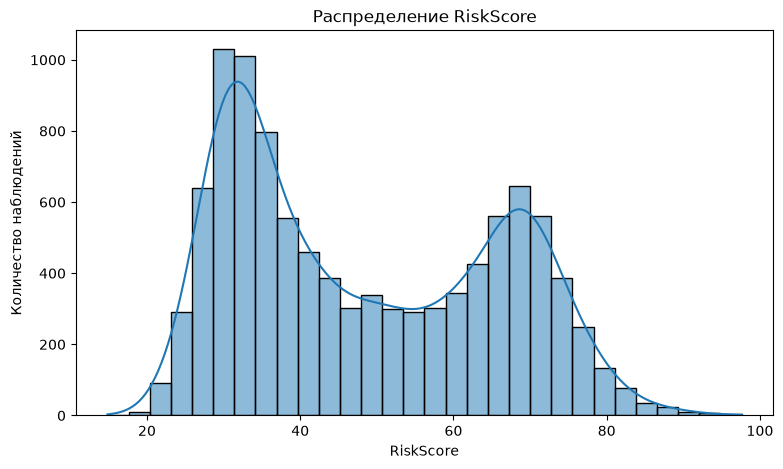

Первые 10 значений ApplicationDate:
0    2010-06-26
1    1996-09-23
2    2015-01-19
3    1981-05-12
4    1995-05-07
5    1997-05-12
6    1987-04-06
7    1989-05-09
8    1989-09-03
9    1985-02-28
Name: ApplicationDate, dtype: str

Количество уникальных дат:
9788

Минимальная и максимальная даты:
1979-01-01
2020-01-25


In [19]:
plt.figure(figsize=(9, 5))
sns.histplot(train_clean["RiskScore"], bins=30, kde=True)
plt.title("Распределение RiskScore")
plt.xlabel("RiskScore")
plt.ylabel("Количество наблюдений")
plt.show()

print("Первые 10 значений ApplicationDate:")
print(train_clean["ApplicationDate"].head(10))

print("\nКоличество уникальных дат:")
print(train_clean["ApplicationDate"].nunique())

print("\nМинимальная и максимальная даты:")
print(train_clean["ApplicationDate"].min())
print(train_clean["ApplicationDate"].max())

Пересоберем дату как год, месяц, день

In [ ]:
train_clean["ApplicationDate"] = pd.to_datetime(
    train_clean["ApplicationDate"]
)

train_clean["ApplicationYear"] = train_clean["ApplicationDate"].dt.year
train_clean["ApplicationMonth"] = train_clean["ApplicationDate"].dt.month
train_clean["ApplicationDay"] = train_clean["ApplicationDate"].dt.day

train_clean = train_clean.drop(columns=["ApplicationDate"])

print(train_clean[
    ["ApplicationYear", "ApplicationMonth", "ApplicationDay"]
].head())

print("\nНовый размер данных:", train_clean.shape)

   ApplicationYear  ApplicationMonth  ApplicationDay
0             2010                 6              26
1             1996                 9              23
2             2015                 1              19
3             1981                 5              12
4             1995                 5               7

Новый размер данных: (10272, 37)


Какова корреляция с целевой переменной

Корреляции признаков с RiskScore:
CreditScore                  -0.785425
MonthlyIncome                -0.770267
BaseInterestRate              0.758712
AnnualIncome                 -0.758514
InterestRate                  0.742634
TotalDebtToIncomeRatio        0.530729
BankruptcyHistory             0.177559
MonthlyLoanPayment            0.150830
TotalAssets                  -0.145735
NetWorth                     -0.144574
DebtToIncomeRatio             0.110862
LoanAmount                    0.084978
LengthOfCreditHistory        -0.061454
CreditCardUtilizationRate     0.056063
PreviousLoanDefaults          0.054959
Experience                   -0.046795
Age                          -0.044272
LoanDuration                  0.028269
UtilityBillsPaymentHistory    0.026535
PaymentHistory                0.019917
MonthlyDebtPayments           0.018366
TotalLiabilities              0.017198
NumberOfCreditInquiries      -0.016380
JobTenure                     0.014251
ApplicationDay               -

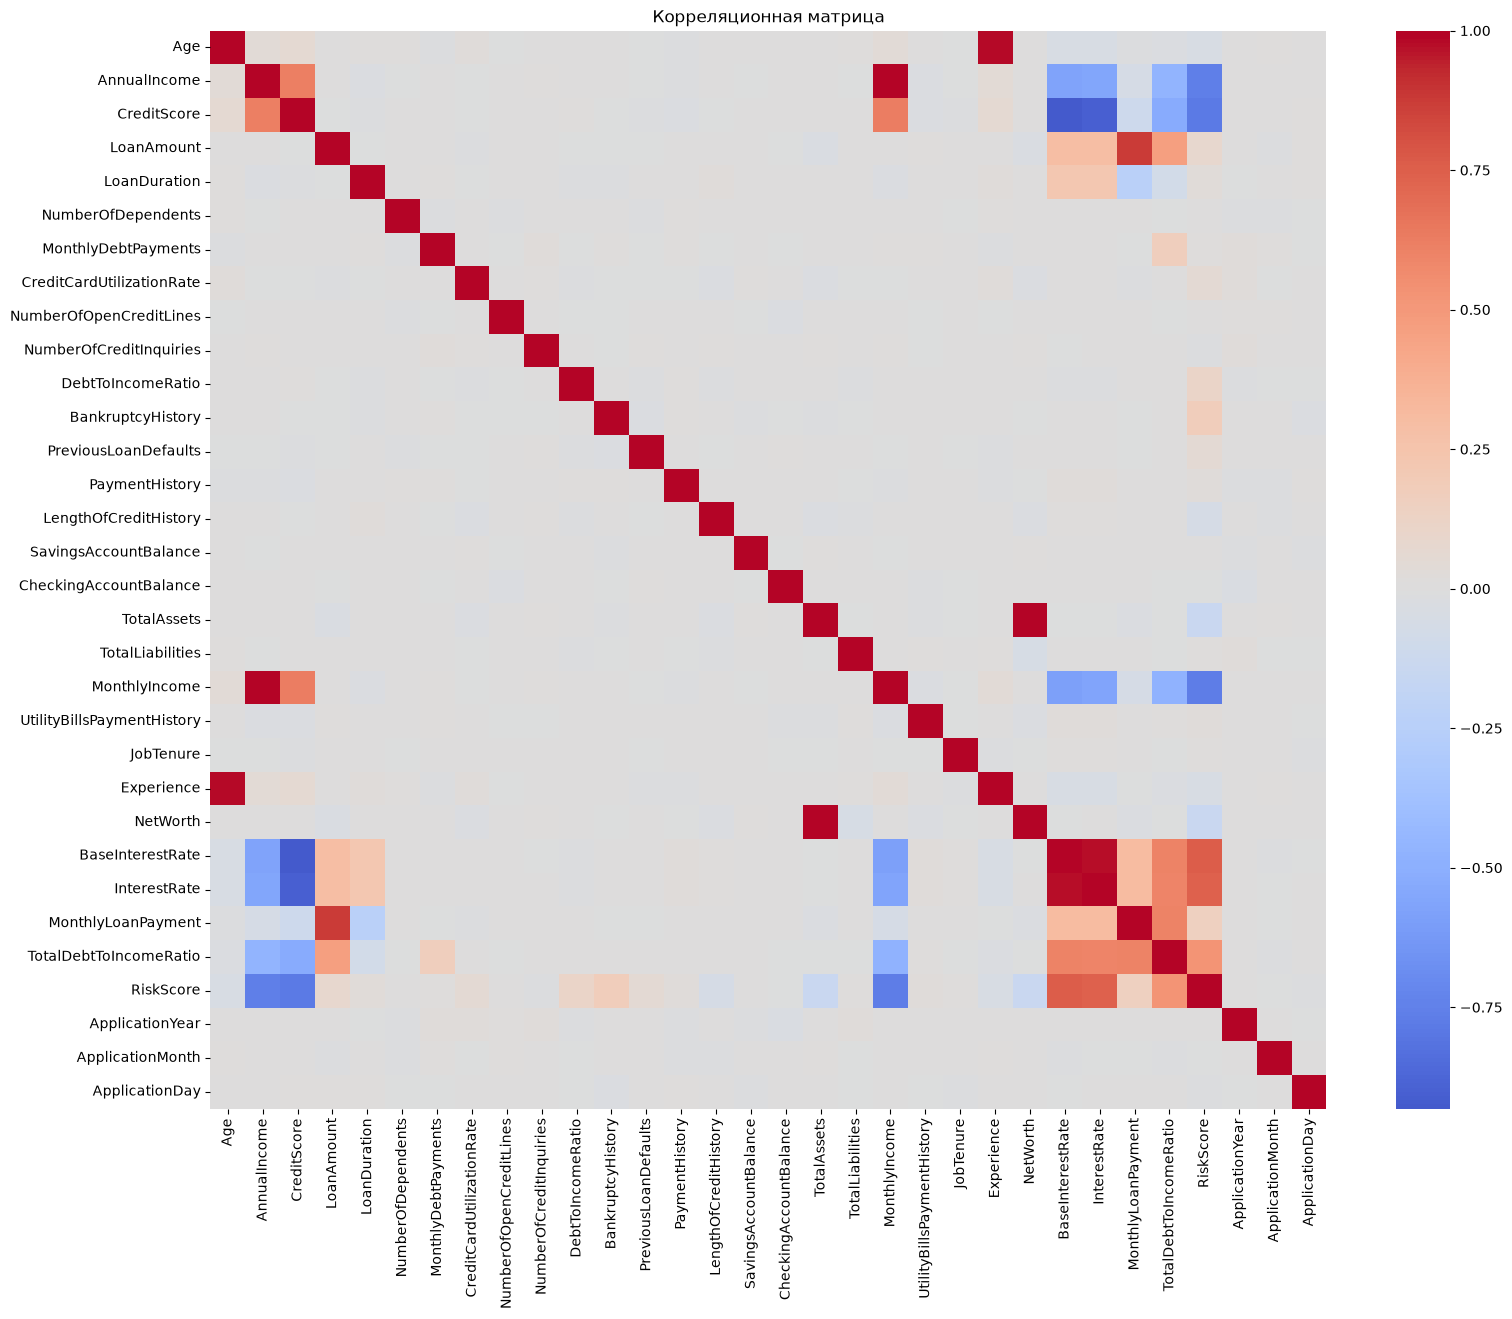

In [21]:
correlation_matrix = train_clean.corr(numeric_only=True)

target_correlations = (
    correlation_matrix["RiskScore"]
    .drop("RiskScore")
    .sort_values(key=abs, ascending=False)
)

print("Корреляции признаков с RiskScore:")
print(target_correlations)

plt.figure(figsize=(18, 14))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)
plt.title("Корреляционная матрица")
plt.show()

На график повлипали, теперь найдем явно

In [22]:
feature_corr = train_clean.drop(
    columns=["RiskScore"]
).corr(numeric_only=True)

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

strong_pairs = (
    upper_triangle.stack()
    .sort_values(key=abs, ascending=False)
)

print("15 самых сильно коррелирующих пар признаков:")
print(strong_pairs.head(15))

15 самых сильно коррелирующих пар признаков:
TotalAssets         NetWorth                  0.993996
AnnualIncome        MonthlyIncome             0.985438
Age                 Experience                0.982964
BaseInterestRate    InterestRate              0.975344
CreditScore         BaseInterestRate         -0.931577
                    InterestRate             -0.907192
LoanAmount          MonthlyLoanPayment        0.872616
CreditScore         MonthlyIncome             0.628032
AnnualIncome        CreditScore               0.617930
BaseInterestRate    TotalDebtToIncomeRatio    0.606349
MonthlyLoanPayment  TotalDebtToIncomeRatio    0.603141
InterestRate        TotalDebtToIncomeRatio    0.599626
MonthlyIncome       BaseInterestRate         -0.585249
AnnualIncome        BaseInterestRate         -0.575853
MonthlyIncome       InterestRate             -0.568472
dtype: float64


Вывод(1): ### Анализ корреляционной матрицы

В ходе анализа корреляционной матрицы Пирсона были обнаружены признаки с сильной линейной связью с целевой переменной `RiskScore`.

Наиболее высокая отрицательная корреляция наблюдается у `CreditScore` (-0.785), `MonthlyIncome` (-0.770) и `AnnualIncome` (-0.759). Наиболее высокая положительная корреляция наблюдается у `BaseInterestRate` (0.759) и `InterestRate` (0.743).

Также выявлены пары признаков с очень высокой взаимной корреляцией: `TotalAssets` и `NetWorth` (0.994), `AnnualIncome` и `MonthlyIncome` (0.985), `Age` и `Experience` (0.983), `BaseInterestRate` и `InterestRate` (0.975).

Такие зависимости могут указывать на мультиколлинеарность, которая способна приводить к нестабильности коэффициентов линейной регрессии. Поэтому влияние этих признаков на качество модели будет дополнительно исследовано экспериментально.

### Графики зависимостей

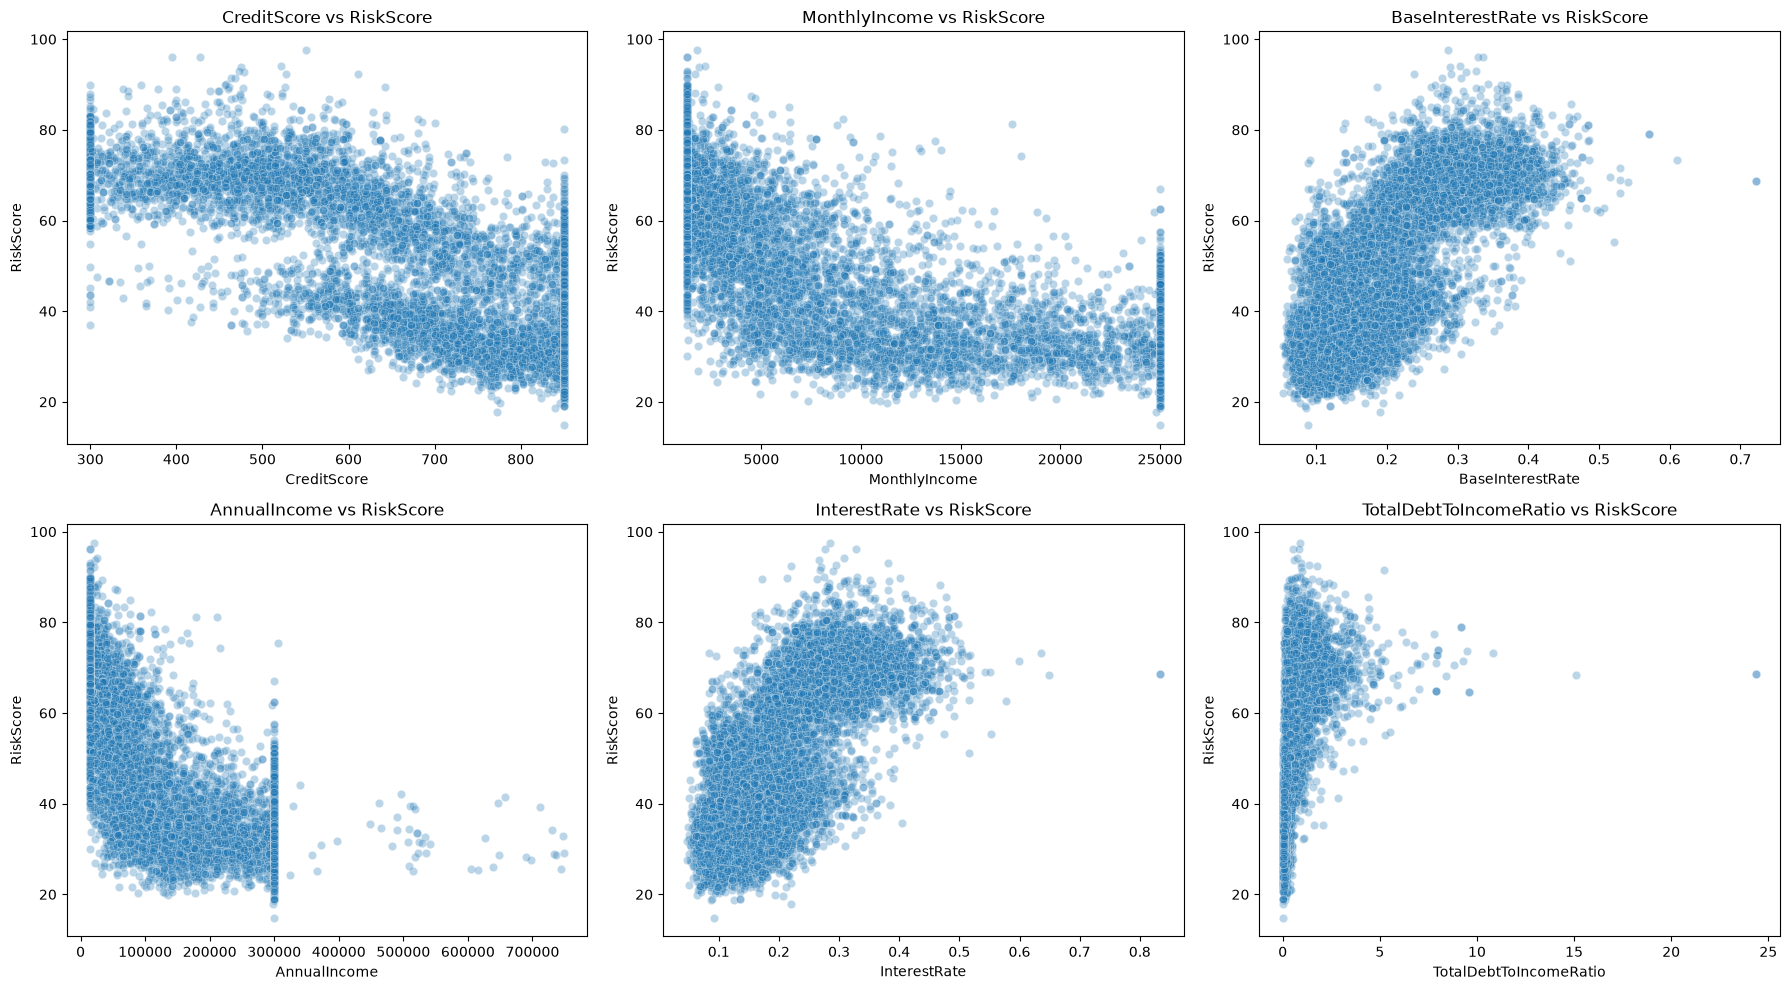

In [23]:
top_features = [
    "CreditScore",
    "MonthlyIncome",
    "BaseInterestRate",
    "AnnualIncome",
    "InterestRate",
    "TotalDebtToIncomeRatio"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for feature, ax in zip(top_features, axes.flat):
    sns.scatterplot(
        data=train_clean,
        x=feature,
        y="RiskScore",
        alpha=0.3,
        ax=ax
    )
    ax.set_title(f"{feature} vs RiskScore")

plt.tight_layout()
plt.show()

In [24]:
for feature in categorical_features:
    print(f"\n--- {feature} ---")
    print("Количество категорий:", train_clean[feature].nunique())
    print(train_clean[feature].value_counts(dropna=False))


--- MaritalStatus ---
Количество категорий: 4
MaritalStatus
Married     5023
Single      3163
Divorced    1536
Widowed      550
Name: count, dtype: int64

--- HomeOwnershipStatus ---
Количество категорий: 4
HomeOwnershipStatus
Mortgage    4057
Rent        3115
Own         2081
Other       1019
Name: count, dtype: int64

--- LoanPurpose ---
Количество категорий: 5
LoanPurpose
Home                  2919
Debt Consolidation    2407
Auto                  1968
Education             1573
Other                  920
NaN                    485
Name: count, dtype: int64

--- EmploymentStatus ---
Количество категорий: 3
EmploymentStatus
Employed         8884
Self-Employed     966
Unemployed        422
Name: count, dtype: int64

--- EducationLevel ---
Количество категорий: 5
EducationLevel
High School    4150
Bachelor       3026
Associate      2019
Master          738
Doctorate       339
Name: count, dtype: int64


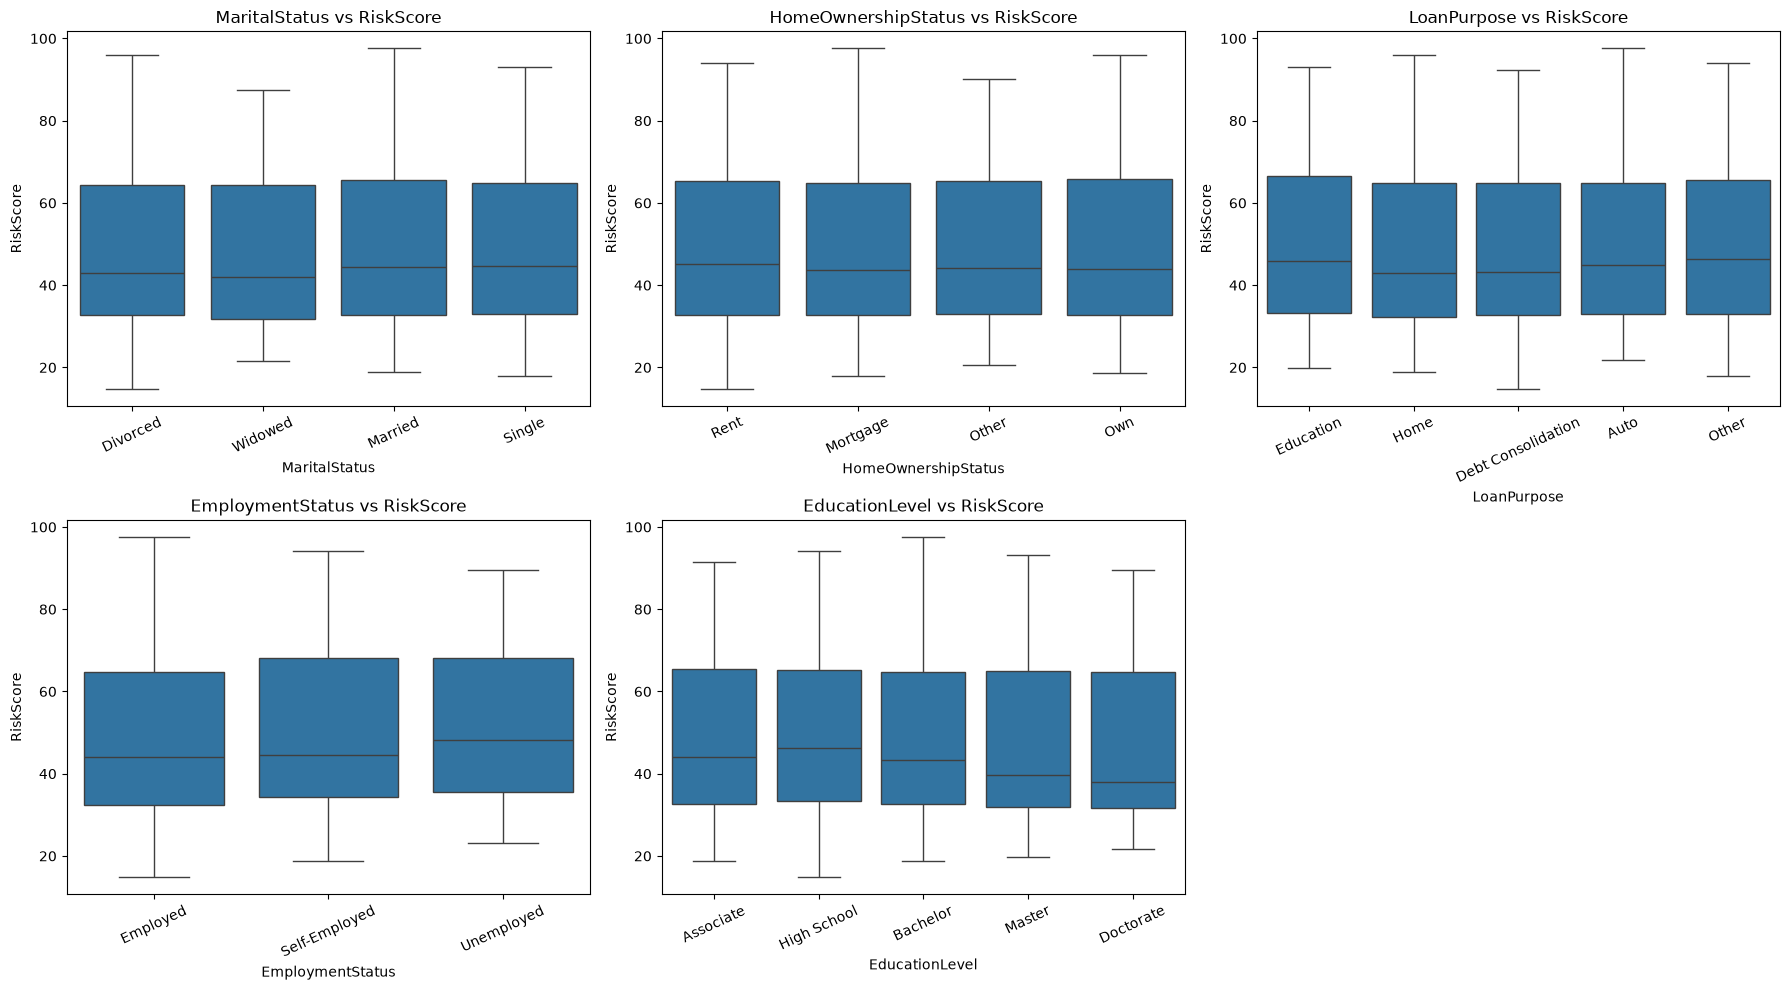

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for feature, ax in zip(categorical_features, axes.flat):
    sns.boxplot(
        data=train_clean,
        x=feature,
        y="RiskScore",
        ax=ax
    )
    ax.set_title(f"{feature} vs RiskScore")
    ax.tick_params(axis="x", rotation=25)

fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

In [26]:
for feature in categorical_features:
    print(f"\n--- {feature} ---")

    print(
        train_clean.groupby(feature, dropna=False)["RiskScore"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )


--- MaritalStatus ---
               count   mean  median    std
MaritalStatus                             
Divorced        1536  47.65   42.86  17.00
Married         5023  48.62   44.51  17.40
Single          3163  48.43   44.78  17.12
Widowed          550  47.54   42.11  17.15

--- HomeOwnershipStatus ---
                     count   mean  median    std
HomeOwnershipStatus                             
Mortgage              4057  48.11   43.69  17.18
Other                 1019  48.41   44.06  17.12
Own                   2081  48.57   43.98  17.42
Rent                  3115  48.53   45.09  17.24

--- LoanPurpose ---
                    count   mean  median    std
LoanPurpose                                    
Auto                 1968  48.33   44.86  17.05
Debt Consolidation   2407  47.94   43.11  17.17
Education            1573  49.48   45.87  17.66
Home                 2919  47.87   42.85  17.20
Other                 920  49.04   46.30  17.31
NaN                   485  48.53   44.7

Вывод(2): ### Анализ категориальных признаков

Для исследования категориальных признаков были рассчитаны количество наблюдений, среднее значение, медиана и стандартное отклонение целевой переменной RiskScore для каждой категории.

Наиболее заметные различия наблюдаются для признака EmploymentStatus: средний RiskScore составляет 48.01 для работающих, 50.17 для самозанятых и 51.58 для безработных.

Для признаков MaritalStatus и HomeOwnershipStatus средние значения RiskScore между категориями отличаются незначительно.

Для LoanPurpose и EducationLevel также наблюдаются некоторые различия, однако они относительно невелики по сравнению с внутригрупповым разбросом целевой переменной.

Таким образом, категориальные признаки могут содержать полезную информацию, но их индивидуальная связь с RiskScore выражена слабее, чем у некоторых числовых признаков. Для дальнейшего использования в линейной регрессии они будут преобразованы методом One-Hot Encoding.

## Подготовка данных к линейной регрессии

Разделим данные на признаки, по которым модель будет предсказывать риск, правильные значения и выборки(обучеющую и проверочную)

In [ ]:
from sklearn.model_selection import train_test_split

X = train_clean.drop(columns=["RiskScore"])
y = train_clean["RiskScore"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Размер X_train:", X_train.shape)
print("Размер X_val:", X_val.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_val:", y_val.shape)

Размер X_train: (8217, 36)
Размер X_val: (2055, 36)
Размер y_train: (8217,)
Размер y_val: (2055,)


In [28]:
print("Пропуски в X_train:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nПропуски в X_val:")
print(X_val.isnull().sum()[X_val.isnull().sum() > 0])

Пропуски в X_train:
CreditScore               386
LoanAmount                386
MonthlyDebtPayments       386
BankruptcyHistory         386
LoanPurpose               386
CheckingAccountBalance    386
TotalAssets               386
NetWorth                  386
BaseInterestRate          386
dtype: int64

Пропуски в X_val:
CreditScore               99
LoanAmount                99
MonthlyDebtPayments       99
BankruptcyHistory         99
LoanPurpose               99
CheckingAccountBalance    99
TotalAssets               99
NetWorth                  99
BaseInterestRate          99
dtype: int64


Вычислим наиболее частые категории по тренировочной выборке и заполним ими проверочную, так мы избежим утечки данных

In [ ]:
X_train = X_train.copy()
X_val = X_val.copy()

numerical_medians = X_train[numerical_features].median()

X_train[numerical_features] = X_train[numerical_features].fillna(
    numerical_medians
)

X_val[numerical_features] = X_val[numerical_features].fillna(
    numerical_medians
)

categorical_modes = X_train[categorical_features].mode().iloc[0]

X_train[categorical_features] = X_train[categorical_features].fillna(
    categorical_modes
)

X_val[categorical_features] = X_val[categorical_features].fillna(
    categorical_modes
)

print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_val:", X_val.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_val: 0


In [ ]:
X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_val = pd.get_dummies(
    X_val,
    columns=categorical_features,
    dtype=int
)

X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Размер X_train:", X_train.shape)
print("Размер X_val:", X_val.shape)

print("\nВсе признаки числовые:")
print(X_train.select_dtypes(exclude=["number"]).columns.tolist())

print("\nКоличество пропусков:")
print("X_train:", X_train.isnull().sum().sum())
print("X_val:", X_val.isnull().sum().sum())

Размер X_train: (8217, 52)
Размер X_val: (2055, 52)

Все признаки числовые:
[]

Количество пропусков:
X_train: 0
X_val: 0


### Два метода нормализации

Z-score normalization

In [31]:
z_mean = X_train.mean()
z_std = X_train.std(ddof=0)

z_std = z_std.replace(0, 1)

X_train_z = (X_train - z_mean) / z_std
X_val_z = (X_val - z_mean) / z_std

print("Средние значения после Z-score:")
print(X_train_z.mean().round(4).head(10))

print("\nСтандартные отклонения после Z-score:")
print(X_train_z.std(ddof=0).round(4).head(10))

Средние значения после Z-score:
Age                         -0.0
AnnualIncome                 0.0
CreditScore                 -0.0
LoanAmount                  -0.0
LoanDuration                -0.0
NumberOfDependents           0.0
MonthlyDebtPayments         -0.0
CreditCardUtilizationRate    0.0
NumberOfOpenCreditLines     -0.0
NumberOfCreditInquiries      0.0
dtype: float64

Стандартные отклонения после Z-score:
Age                          1.0
AnnualIncome                 1.0
CreditScore                  1.0
LoanAmount                   1.0
LoanDuration                 1.0
NumberOfDependents           1.0
MonthlyDebtPayments          1.0
CreditCardUtilizationRate    1.0
NumberOfOpenCreditLines      1.0
NumberOfCreditInquiries      1.0
dtype: float64


Min-Max нормализация

In [32]:
# Находим минимум и максимум по обучающей выборке
min_values = X_train.min()
max_values = X_train.max()

# Разница между максимумом и минимумом
value_range = max_values - min_values

# Защита от деления на ноль
value_range = value_range.replace(0, 1)

# Min-Max нормализация
X_train_mm = (X_train - min_values) / value_range
X_val_mm = (X_val - min_values) / value_range

print("Минимальные значения после Min-Max:")
print(X_train_mm.min().round(4).head(10))

print("\nМаксимальные значения после Min-Max:")
print(X_train_mm.max().round(4).head(10))

Минимальные значения после Min-Max:
Age                          0.0
AnnualIncome                 0.0
CreditScore                  0.0
LoanAmount                   0.0
LoanDuration                 0.0
NumberOfDependents           0.0
MonthlyDebtPayments          0.0
CreditCardUtilizationRate    0.0
NumberOfOpenCreditLines      0.0
NumberOfCreditInquiries      0.0
dtype: float64

Максимальные значения после Min-Max:
Age                          1.0
AnnualIncome                 1.0
CreditScore                  1.0
LoanAmount                   1.0
LoanDuration                 1.0
NumberOfDependents           1.0
MonthlyDebtPayments          1.0
CreditCardUtilizationRate    1.0
NumberOfOpenCreditLines      1.0
NumberOfCreditInquiries      1.0
dtype: float64


Переходим к линейной регрессии

In [33]:
X_train_array = X_train_z.to_numpy()
X_val_array = X_val_z.to_numpy()

y_train_array = y_train.to_numpy()
y_val_array = y_val.to_numpy()

print("X_train:", X_train_array.shape)
print("X_val:", X_val_array.shape)
print("y_train:", y_train_array.shape)
print("y_val:", y_val_array.shape)

X_train: (8217, 52)
X_val: (2055, 52)
y_train: (8217,)
y_val: (2055,)


Создадим класс для собственной линейной регрессии

In [34]:
class MyLinearRegression:

    def fit(self, X, y):
        # Добавляем столбец единиц для свободного коэффициента
        X_with_bias = np.c_[np.ones(X.shape[0]), X]

        # Вычисляем коэффициенты аналитически
        self.weights = np.linalg.pinv(
            X_with_bias.T @ X_with_bias
        ) @ X_with_bias.T @ y

        return self

    def predict(self, X):
        # Добавляем столбец единиц
        X_with_bias = np.c_[np.ones(X.shape[0]), X]

        # Получаем предсказания
        return X_with_bias @ self.weights

In [35]:
model_analytical = MyLinearRegression()

model_analytical.fit(X_train_array, y_train_array)

predictions = model_analytical.predict(X_val_array)

print("Количество коэффициентов:", len(model_analytical.weights))
print("Первые 10 коэффициентов:")
print(model_analytical.weights[:10])

print("\nПервые 10 предсказаний:")
print(predictions[:10])

Количество коэффициентов: 53
Первые 10 коэффициентов:
[ 4.84739475e+01  2.51838732e-01  2.83956774e-01 -2.71434202e+00
 -1.17254003e-01 -1.03282459e+00  4.26663731e-04  3.49165135e-01
  8.83783320e-01 -1.74062396e-02]

Первые 10 предсказаний:
[48.0257102  75.71610564 25.03005343 58.14004632 41.97298061 73.10254885
 -3.20383738 38.13500085 62.49473069 61.33138152]


Че-то как-то обучили, давайте чекать. Работаем с MSE

In [36]:
mse_analytical = np.mean((y_val_array - predictions) ** 2)

print("MSE нашей модели:", mse_analytical)

MSE нашей модели: 53.8883319015116


In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

sklearn_model = LinearRegression()
sklearn_model.fit(X_train_array, y_train_array)

sklearn_predictions = sklearn_model.predict(X_val_array)

sklearn_mse = mean_squared_error(y_val_array, sklearn_predictions)

print("MSE нашей модели:", mse_analytical)
print("MSE sklearn:", sklearn_mse)
print("Разница:", abs(mse_analytical - sklearn_mse))

MSE нашей модели: 53.8883319015116
MSE sklearn: 53.85312578435701
Разница: 0.03520611715458699


In [38]:
class MyLinearRegressionGD:

    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X_with_bias = np.c_[np.ones(X.shape[0]), X]

        n_samples, n_features = X_with_bias.shape

        self.weights = np.zeros(n_features)

        self.loss_history = []

        for _ in range(self.n_iterations):
            predictions = X_with_bias @ self.weights

            errors = predictions - y

            gradient = (2 / n_samples) * (X_with_bias.T @ errors)

            self.weights -= self.learning_rate * gradient

            mse = np.mean(errors ** 2)
            self.loss_history.append(mse)

        return self

    def predict(self, X):
        X_with_bias = np.c_[np.ones(X.shape[0]), X]
        return X_with_bias @ self.weights

Gradient Descent

In [39]:
model_gd = MyLinearRegressionGD(
    learning_rate=0.01,
    n_iterations=1000
)

model_gd.fit(X_train_array, y_train_array)

gd_predictions = model_gd.predict(X_val_array)

gd_mse = np.mean((y_val_array - gd_predictions) ** 2)

print("MSE Gradient Descent:", gd_mse)
print("Последняя ошибка обучения:", model_gd.loss_history[-1])

MSE Gradient Descent: 54.031116611865286
Последняя ошибка обучения: 52.29237293385201


Графики как всегда никто не отменял

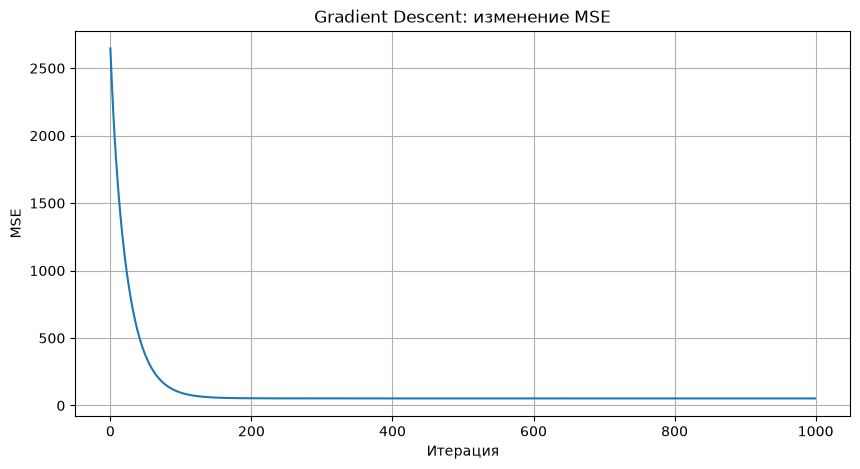

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(model_gd.loss_history)

plt.title("Gradient Descent: изменение MSE")
plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.grid(True)

plt.show()

3 версия, а вы ждали, что все с первого раза выйдетб не выйдет, ладно, 3 версия из задания SGD

In [41]:
class MyLinearRegressionSGD:

    def __init__(self, learning_rate=0.001, n_epochs=50):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs

    def fit(self, X, y):
        X_with_bias = np.c_[np.ones(X.shape[0]), X]

        n_samples, n_features = X_with_bias.shape

        self.weights = np.zeros(n_features)
        self.loss_history = []

        for epoch in range(self.n_epochs):
            indices = np.random.permutation(n_samples)

            for i in indices:
                prediction = X_with_bias[i] @ self.weights
                error = prediction - y[i]

                gradient = 2 * X_with_bias[i] * error

                self.weights -= self.learning_rate * gradient

            predictions = X_with_bias @ self.weights
            mse = np.mean((predictions - y) ** 2)

            self.loss_history.append(mse)

        return self

    def predict(self, X):
        X_with_bias = np.c_[np.ones(X.shape[0]), X]
        return X_with_bias @ self.weights

In [42]:
model_sgd = MyLinearRegressionSGD(
    learning_rate=0.001,
    n_epochs=50
)

model_sgd.fit(X_train_array, y_train_array)

sgd_predictions = model_sgd.predict(X_val_array)

sgd_mse = np.mean((y_val_array - sgd_predictions) ** 2)

print("MSE SGD:", sgd_mse)
print("Последняя ошибка обучения:", model_sgd.loss_history[-1])

MSE SGD: 57.66847507343315
Последняя ошибка обучения: 54.62460029383118


### Переходим к метрикам

In [43]:
def my_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def my_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


def my_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - ss_res / ss_tot


def my_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

Функции созданы, теперь проверка

In [44]:
print("MSE:", my_mse(y_val_array, predictions))
print("MAE:", my_mae(y_val_array, predictions))
print("R2:", my_r2(y_val_array, predictions))
print("MAPE:", my_mape(y_val_array, predictions))

MSE: 53.8883319015116
MAE: 5.894037657564827
R2: 0.8198035800099832
MAPE: 14.050620455814297


In [45]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

print("MSE sklearn:", mean_squared_error(y_val_array, predictions))
print("MAE sklearn:", mean_absolute_error(y_val_array, predictions))
print("R2 sklearn:", r2_score(y_val_array, predictions))
print("MAPE sklearn:", mean_absolute_percentage_error(
    y_val_array, predictions
) * 100)

MSE sklearn: 53.8883319015116
MAE sklearn: 5.894037657564827
R2 sklearn: 0.8198035800099832
MAPE sklearn: 14.050620455814297


### Реализуем собственный K-Fold Cross-Validation

In [46]:
def my_kfold(n_samples, n_splits=5, shuffle=True, random_state=42):
    indices = np.arange(n_samples)

    if shuffle:
        rng = np.random.default_rng(random_state)
        rng.shuffle(indices)

    folds = np.array_split(indices, n_splits)

    for i in range(n_splits):
        val_indices = folds[i]
        train_indices = np.concatenate(
            [folds[j] for j in range(n_splits) if j != i]
        )

        yield train_indices, val_indices

In [47]:
fold_number = 1

for train_idx, val_idx in my_kfold(len(X_train_array), n_splits=5):

    print(f"Fold {fold_number}:")
    print("Train:", len(train_idx))
    print("Validation:", len(val_idx))
    print()

    fold_number += 1

Fold 1:
Train: 6573
Validation: 1644

Fold 2:
Train: 6573
Validation: 1644

Fold 3:
Train: 6574
Validation: 1643

Fold 4:
Train: 6574
Validation: 1643

Fold 5:
Train: 6574
Validation: 1643



Теперь 5 разделений

In [48]:
fold_mse_scores = []

for fold_number, (train_idx, val_idx) in enumerate(
    my_kfold(len(X_train_array), n_splits=5),
    start=1
):
    X_fold_train = X_train_array[train_idx]
    y_fold_train = y_train_array[train_idx]

    X_fold_val = X_train_array[val_idx]
    y_fold_val = y_train_array[val_idx]

    model = MyLinearRegression()
    model.fit(X_fold_train, y_fold_train)

    fold_predictions = model.predict(X_fold_val)

    fold_mse = my_mse(y_fold_val, fold_predictions)
    fold_mse_scores.append(fold_mse)

    print(f"Fold {fold_number} MSE: {fold_mse:.4f}")

print("\nСредний MSE:", np.mean(fold_mse_scores))
print("Стандартное отклонение MSE:", np.std(fold_mse_scores))

Fold 1 MSE: 51.8023
Fold 2 MSE: 50.4708
Fold 3 MSE: 51.6805
Fold 4 MSE: 55.5343
Fold 5 MSE: 54.8422

Средний MSE: 52.86603242676923
Стандартное отклонение MSE: 1.9646421883267255


Реализуем собственный генератор LOOCV

In [49]:
def my_loocv(n_samples):
    indices = np.arange(n_samples)

    for i in range(n_samples):
        val_index = np.array([i])
        train_indices = np.delete(indices, i)

        yield train_indices, val_index

In [50]:
for fold, (train_idx, val_idx) in enumerate(my_loocv(5), start=1):
    print(f"Итерация {fold}")
    print("Train:", train_idx)
    print("Validation:", val_idx)
    print()

Итерация 1
Train: [1 2 3 4]
Validation: [0]

Итерация 2
Train: [0 2 3 4]
Validation: [1]

Итерация 3
Train: [0 1 3 4]
Validation: [2]

Итерация 4
Train: [0 1 2 4]
Validation: [3]

Итерация 5
Train: [0 1 2 3]
Validation: [4]



In [51]:
X_loocv = X_train_array[:100]
y_loocv = y_train_array[:100]

loocv_predictions = []

for train_idx, val_idx in my_loocv(len(X_loocv)):

    X_fold_train = X_loocv[train_idx]
    y_fold_train = y_loocv[train_idx]

    X_fold_val = X_loocv[val_idx]

    model = MyLinearRegression()
    model.fit(X_fold_train, y_fold_train)

    prediction = model.predict(X_fold_val)

    loocv_predictions.append(prediction[0])

loocv_predictions = np.array(loocv_predictions)

loocv_mse = my_mse(y_loocv, loocv_predictions)

print("Количество обучений:", len(loocv_predictions))
print("LOOCV MSE:", loocv_mse)

Количество обучений: 100
LOOCV MSE: 151.5445552962162


Сводная таблица результатов

In [52]:
results = pd.DataFrame({
    "Method": [
        "Analytical",
        "Gradient Descent",
        "Stochastic Gradient Descent"
    ],
    "MSE": [
        my_mse(y_val_array, predictions),
        my_mse(y_val_array, gd_predictions),
        my_mse(y_val_array, sgd_predictions)
    ],
    "MAE": [
        my_mae(y_val_array, predictions),
        my_mae(y_val_array, gd_predictions),
        my_mae(y_val_array, sgd_predictions)
    ],
    "R2": [
        my_r2(y_val_array, predictions),
        my_r2(y_val_array, gd_predictions),
        my_r2(y_val_array, sgd_predictions)
    ],
    "MAPE": [
        my_mape(y_val_array, predictions),
        my_mape(y_val_array, gd_predictions),
        my_mape(y_val_array, sgd_predictions)
    ]
})

results.round(4)

,Method,MSE,MAE,R2,MAPE
0,Analytical,53.8883,5.8940,0.8198,14.0506
1,Gradient Descent,54.0311,5.8969,0.8193,14.0617
2,Stochastic Gradient Descent,57.6685,6.1139,0.8072,14.5489


In [53]:
import time

# Аналитическое решение
start = time.perf_counter()
MyLinearRegression().fit(X_train_array, y_train_array)
analytical_time = time.perf_counter() - start

# Gradient Descent
start = time.perf_counter()
MyLinearRegressionGD(
    learning_rate=0.01,
    n_iterations=1000
).fit(X_train_array, y_train_array)
gd_time = time.perf_counter() - start

# SGD
start = time.perf_counter()
MyLinearRegressionSGD(
    learning_rate=0.001,
    n_epochs=50
).fit(X_train_array, y_train_array)
sgd_time = time.perf_counter() - start

print(f"Analytical: {analytical_time:.4f} сек")
print(f"Gradient Descent: {gd_time:.4f} сек")
print(f"SGD: {sgd_time:.4f} сек")

Analytical: 0.0140 сек
Gradient Descent: 0.1896 сек
SGD: 2.4476 сек
